In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse
import shap
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

/home/leodemore/anaconda3/envs/amap/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TODAS CATEGÓRICAS, EXCETO AS DUAS ÚLTIMAS (NUMÉRICAS)

In [ ]:
df = pd.read_csv('df_train.csv')
display(df)

,SIT_TRAB,LOC_EXPO,AGENTE_TOX,VIA_1,CIRCUNSTAN,TPEXP,CLASSI_FIN,CS_SEXO,CS_GESTANT,CS_RACA,CS_ESCOL_N,INTERNADO,TEMPO_ATEND,IDADE_ANOS,EVOLUCAO
0,4.0,1.0,2.0,1.0,10.0,1.0,1.0,M,6.0,9.0,9.0,0,0.291667,50.0,1.0
1,12.0,1.0,2.0,1.0,2.0,1.0,2.0,F,6.0,1.0,10.0,1,0.041667,1.0,1.0
2,3.0,6.0,2.0,1.0,10.0,2.0,1.0,M,6.0,2.0,9.0,1,0.208333,29.0,1.0
3,99.0,1.0,2.0,5.0,10.0,1.0,1.0,F,5.0,1.0,5.0,1,0.041667,17.0,1.0
4,99.0,1.0,3.0,1.0,2.0,1.0,2.0,F,6.0,4.0,10.0,0,0.000000,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48610,99.0,1.0,3.0,1.0,2.0,1.0,2.0,F,6.0,4.0,10.0,0,0.041667,3.0,1.0
48611,6.0,1.0,3.0,1.0,2.0,1.0,4.0,M,6.0,1.0,7.0,0,0.041667,64.0,1.0
48612,3.0,1.0,2.0,1.0,10.0,1.0,1.0,M,6.0,4.0,0.0,1,0.083333,54.0,1.0
48613,2.0,2.0,2.0,1.0,1.0,2.0,2.0,M,6.0,4.0,4.0,0,0.166667,29.0,1.0


In [ ]:
# 1 e 2 viram 0, e o 3 vira 1
df['EVOLUCAO'] = df['EVOLUCAO'].replace({1: 0, 2: 0, 3: 1})
df['EVOLUCAO'].value_counts()

EVOLUCAO
0.0    47348
1.0     1267
Name: count, dtype: int64

In [ ]:
# 1. Carregar dados e separar X e y
X = df.drop(columns=['EVOLUCAO'])
y = df['EVOLUCAO']

# 2. Setup do Pré-processamento
num_cols = ['TEMPO_ATEND', 'IDADE_ANOS']
cat_cols = [col for col in X.columns if col not in num_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_cols)
    ])

# 3. Split e Aplicação do Pré-processamento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 4. Balanceamento com SMOTE (Apenas no treino)
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_processed, y_train)

print("Pré-processamento e Balanceamento concluídos com sucesso!")

Pré-processamento e Balanceamento concluídos com sucesso!


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

models = {
    "Decision Tree (Balanceada)": DecisionTreeClassifier(
        max_depth=5,
        class_weight='balanced',
        random_state=42
    ),

    "Random Forest Campeão": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost Campeão": XGBClassifier(
        n_estimators=220,
        learning_rate=0.0372,
        max_depth=5,
        subsample=0.927,
        colsample_bytree=0.962,
        scale_pos_weight=37.36,
        eval_metric='logloss',
        random_state=42
    )
}

# 2. Treinando e Avaliando
for name, model in models.items():
    print(f"\n===============================================================")
    print(f"            RESULTADOS: {name}")
    print(f"===============================================================")

    # Treinamos direto com o dado pré-processado (Os pesos resolvem o desbalanceamento)
    model.fit(X_train_processed, y_train)

    # Previsões de Classe (0 ou 1) e Probabilidades (0.0 a 1.0)
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Exibindo as Métricas
    print(classification_report(y_test, y_pred))

    # Calculando ROC-AUC e PR-AUC
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    print(f"ROC-AUC (Separação Global): {roc_auc:.4f}")
    print(f"PR-AUC  (Foco nos Óbitos) : {pr_auc:.4f}")


            RESULTADOS: Decision Tree (Balanceada)
              precision    recall  f1-score   support

         0.0       1.00      0.77      0.87     14205
         1.0       0.09      0.88      0.17       380

    accuracy                           0.77     14585
   macro avg       0.54      0.82      0.52     14585
weighted avg       0.97      0.77      0.85     14585

ROC-AUC (Separação Global): 0.8961
PR-AUC  (Foco nos Óbitos) : 0.1582

            RESULTADOS: Random Forest Campeão
              precision    recall  f1-score   support

         0.0       1.00      0.77      0.87     14205
         1.0       0.09      0.89      0.17       380

    accuracy                           0.77     14585
   macro avg       0.54      0.83      0.52     14585
weighted avg       0.97      0.77      0.85     14585

ROC-AUC (Separação Global): 0.8936
PR-AUC  (Foco nos Óbitos) : 0.1884

            RESULTADOS: XGBoost Campeão
              precision    recall  f1-score   support

         0.

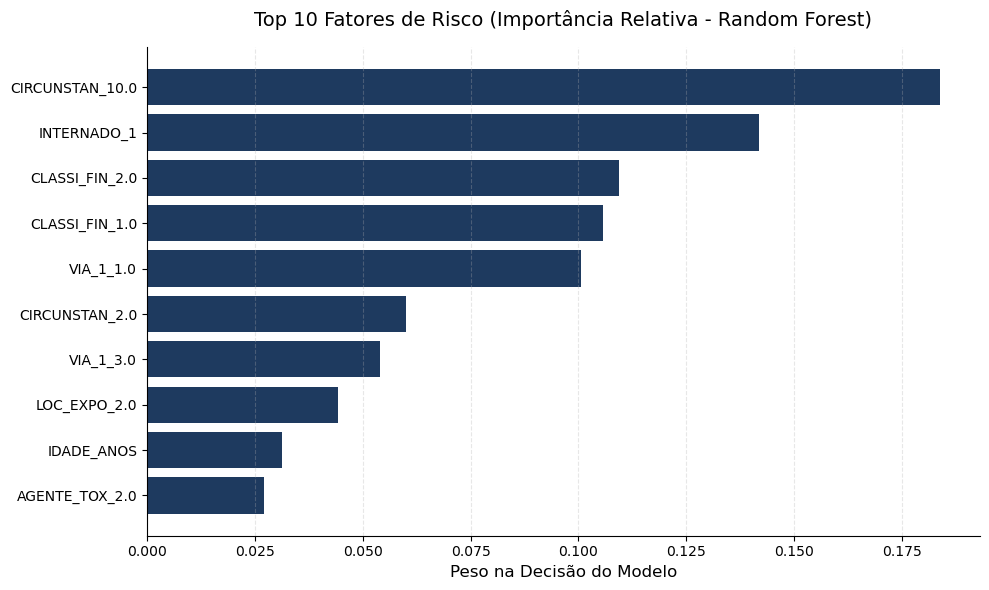

In [ ]:
# Vamos extrair a importância das features do Random Forest Tunado
rf_campeao = models["Random Forest Campeão"]

# Pegando os nomes das colunas processadas
cat_features_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(cat_features_names)

# Montando o DataFrame de Importância
importancias = rf_campeao.feature_importances_
df_imp = pd.DataFrame({'Variavel': all_feature_names, 'Importancia': importancias})
df_imp = df_imp.sort_values(by='Importancia', ascending=True).tail(10)

# Plotagem
plt.figure(figsize=(10, 6))
plt.barh(df_imp['Variavel'], df_imp['Importancia'], color='#1E3A5F')
plt.title('Top 10 Fatores de Risco (Importância Relativa - Random Forest)', fontsize=14, pad=15)
plt.xlabel('Peso na Decisão do Modelo', fontsize=12)
plt.grid(axis='x', alpha=0.3, linestyle='--')
sns.despine()
plt.tight_layout()
plt.show()

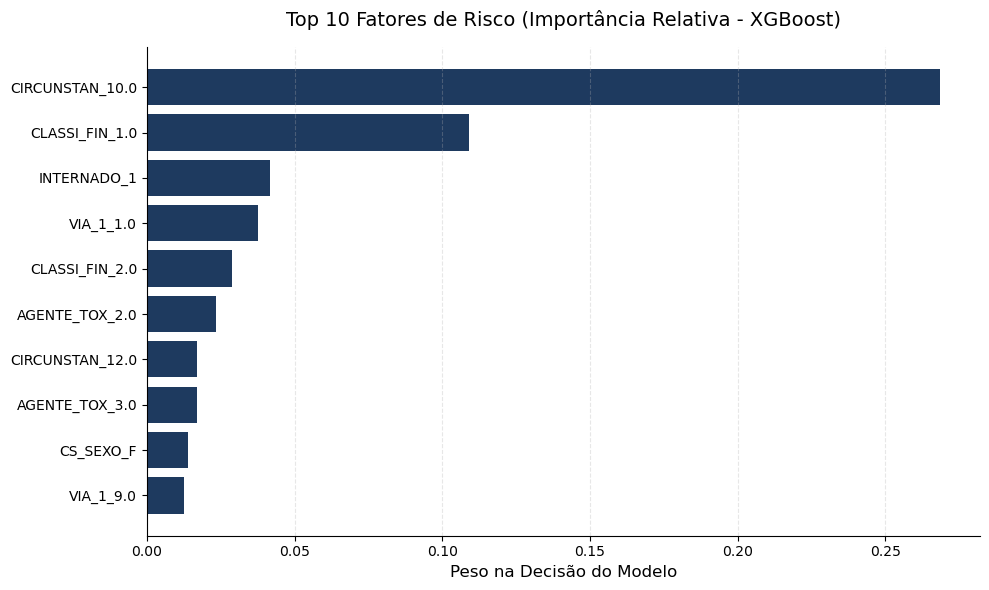

In [ ]:
# 1. Vamos extrair o modelo campeão do seu dicionário
xgb_campeao = models["XGBoost Campeão"]

# 2. Pegando os nomes das colunas processadas
cat_features_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(cat_features_names)

# 3. Montando o DataFrame de Importância
importancias_xgb = xgb_campeao.feature_importances_
df_imp_xgb = pd.DataFrame({'Variavel': all_feature_names, 'Importancia': importancias_xgb})
df_imp_xgb = df_imp_xgb.sort_values(by='Importancia', ascending=True).tail(10)

# 4. Plotagem
plt.figure(figsize=(10, 6))
plt.barh(df_imp_xgb['Variavel'], df_imp_xgb['Importancia'], color='#1E3A5F')
plt.title('Top 10 Fatores de Risco (Importância Relativa - XGBoost)', fontsize=14, pad=15)
plt.xlabel('Peso na Decisão do Modelo', fontsize=12)
plt.grid(axis='x', alpha=0.3, linestyle='--')
sns.despine()
plt.tight_layout()
plt.show()

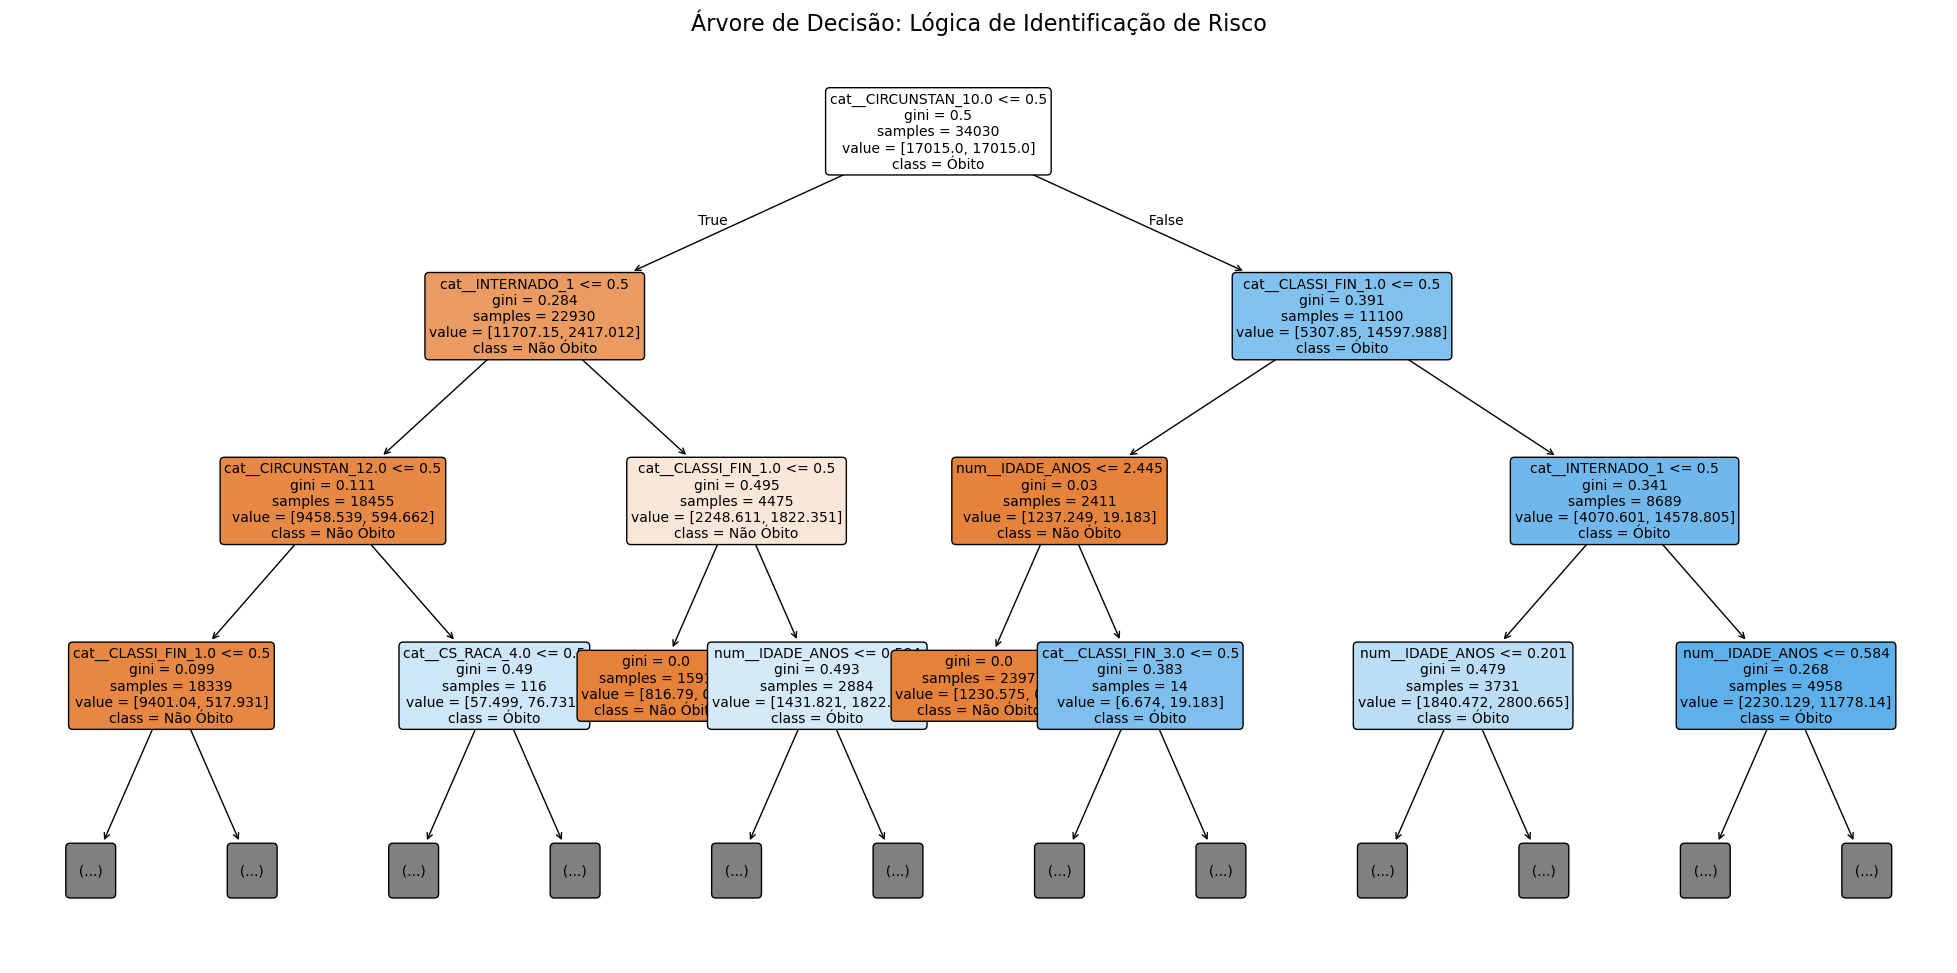

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Extrair os nomes das colunas processadas
# O ColumnTransformer mantém a ordem das transformações: numéricas primeiro, depois categóricas
nomes_colunas = preprocessor.get_feature_names_out()

# 2. Configurar o gráfico
plt.figure(figsize=(25, 12))

# 3. Plotar a árvore
plot_tree(
    models["Decision Tree (Balanceada)"],
    feature_names=nomes_colunas,           # Usa a lista extraída do preprocessor
    class_names=['Não Óbito', 'Óbito'],      # Nomes das classes para facilitar a leitura
    filled=True,                            # Cores que indicam a classe predominante
    rounded=True,                           # Design mais limpo
    fontsize=10,
    max_depth=3                             # Limita a profundidade no plot para legibilidade
)

plt.title("Árvore de Decisão: Lógica de Identificação de Risco", fontsize=16)
plt.show()